In [7]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
import pygeohash as pgh

# ==========================================
# 1. Feature Engineering
# ==========================================
def preprocess_data(df, is_train=True):
    df = df.copy()

    # A. Spatial Features: Decode geohash to latitude and longitude
    # This allows tree models to learn regional proximities natively
    df['lat'] = df['geohash'].apply(lambda x: pgh.decode(x)[0] if pd.notnull(x) else np.nan)
    df['lon'] = df['geohash'].apply(lambda x: pgh.decode(x)[1] if pd.notnull(x) else np.nan)

    # B. Temporal Features: Cyclic encoding for time of day
    def time_to_minutes(t):
        if pd.isnull(t): return np.nan
        h, m = map(int, str(t).split(':'))
        return h * 60 + m

    df['minutes'] = df['timestamp'].apply(time_to_minutes)
    # Sine/Cosine transformation preserves the continuous loop of a 24hr day
    df['time_sin'] = np.sin(2 * np.pi * df['minutes'] / 1440)
    df['time_cos'] = np.cos(2 * np.pi * df['minutes'] / 1440)

    # C. Categorical Mapping & Imputation
    df['LargeVehicles'] = df['LargeVehicles'].map({'Allowed': 1, 'Not Allowed': 0}).fillna(-1)
    df['Landmarks'] = df['Landmarks'].map({'Yes': 1, 'No': 0}).fillna(-1)

    # Basic imputation for Temperature (can be upgraded to group-by geohash imputation)
    df['Temperature'] = df['Temperature'].fillna(df['Temperature'].median())
    df['NumberofLanes'] = df['NumberofLanes'].fillna(df['NumberofLanes'].median())

    # Label encode remaining strings
    cat_cols = ['RoadType', 'Weather']
    for col in cat_cols:
        df[col] = df[col].astype(str)
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])

    # Drop original raw columns
    drop_cols = ['Index', 'geohash', 'timestamp', 'minutes']
    features = df.drop(columns=drop_cols)

    if is_train:
        return features.drop(columns=['demand']), features['demand']
    return features

# ==========================================
# 2. Robust Time-Series Validation & Tuning
# ==========================================
def optimize_hyperparameters(X, y):
    max_day = X['day'].max()

    X_train = X[X['day'] < max_day].drop(columns=['day'])
    y_train = y[X['day'] < max_day]

    X_val = X[X['day'] == max_day].drop(columns=['day'])
    y_val = y[X['day'] == max_day]

    # 1. Convert to DMatrix ONCE outside the loop to save CPU->GPU transfer time
    dtrain = xgb.DMatrix(X_train, label=y_train)
    dval = xgb.DMatrix(X_val, label=y_val)

    def objective(trial):
        params = {
            'objective': 'reg:squarederror',
            'eval_metric': 'rmse',
            'tree_method': 'hist',
            'device': 'cuda',
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 4, 10),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        }

        # 2. Use native xgb.train instead of the scikit-learn wrapper
        model = xgb.train(
            params,
            dtrain,
            num_boost_round=1000,
            evals=[(dval, 'validation')],
            early_stopping_rounds=50,
            verbose_eval=False
        )

        preds = model.predict(dval)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        return rmse

    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=30)

    return study.best_params

# ==========================================
# 3. Main Execution
# ==========================================
if __name__ == "__main__":
    print("Loading data...")
    train_df = pd.read_csv('dataset/train.csv')
    test_df = pd.read_csv('dataset/test.csv')

    print("Engineering features...")
    X_train_full, y_train_full = preprocess_data(train_df, is_train=True)
    X_test = preprocess_data(test_df, is_train=False)

    print("Tuning hyperparameters (Time-Series Split)...")
    best_params = optimize_hyperparameters(X_train_full, y_train_full)
    print(f"\nBest parameters found: {best_params}")

    # Ensure GPU parameters are set for the final runs
    best_params['tree_method'] = 'hist'
    best_params['device'] = 'cuda'

    # ==========================================
    # NEW: Calculate Training and Validation Scores
    # ==========================================
    print("\n--- Evaluating Model Scores ---")
    # Re-create the time-series split to calculate exact local scores
    max_day = X_train_full['day'].max()

    X_train_split = X_train_full[X_train_full['day'] < max_day].drop(columns=['day'])
    y_train_split = y_train_full[X_train_full['day'] < max_day]

    X_val_split = X_train_full[X_train_full['day'] == max_day].drop(columns=['day'])
    y_val_split = y_train_full[X_train_full['day'] == max_day]

    dtrain_split = xgb.DMatrix(X_train_split, label=y_train_split)
    dval_split = xgb.DMatrix(X_val_split, label=y_val_split)

    eval_model = xgb.train(
        best_params,
        dtrain_split,
        num_boost_round=1500,
        evals=[(dtrain_split, 'Train'), (dval_split, 'Validation')],
        early_stopping_rounds=50,
        verbose_eval=100  # Prints progress every 100 rounds
    )

    # Print final calculated metrics
    train_preds = eval_model.predict(dtrain_split)
    val_preds = eval_model.predict(dval_split)

    train_rmse = np.sqrt(mean_squared_error(y_train_split, train_preds))
    val_rmse = np.sqrt(mean_squared_error(y_val_split, val_preds))

    print("\n" + "="*50)
    print(f"FINAL TRAINING RMSE:   {train_rmse:.5f}")
    print(f"FINAL VALIDATION RMSE: {val_rmse:.5f} <-- (Expected Leaderboard Score)")
    print("="*50 + "\n")

    # ==========================================
    # Retrain on 100% of data for Final Submission
    # ==========================================
    print("Retraining model on 100% of data for final submission...")
    # Trick: We use the best_iteration from the evaluation model to prevent overfitting
    # since we can't use early stopping when training on 100% of the data.
    optimal_rounds = eval_model.best_iteration

    X_train_final = X_train_full.drop(columns=['day'])
    dtrain_full = xgb.DMatrix(X_train_final, label=y_train_full)

    final_model = xgb.train(
        best_params,
        dtrain_full,
        num_boost_round=optimal_rounds
    )

    print("Generating predictions...")
    X_test_final = X_test.drop(columns=['day'])
    dtest = xgb.DMatrix(X_test_final)
    predictions = final_model.predict(dtest)

    # Save submission
    sub = pd.DataFrame({
        'Index': test_df['Index'],
        'demand': predictions
    })
    sub.to_csv('submission_xgb_optuna2.csv', index=False)
    print("Submission saved to 'submission_xgb_optuna.csv'")

Loading data...
Engineering features...


[I 2026-05-31 12:44:34,930] A new study created in memory with name: no-name-de9b4b8b-0a88-4c60-989d-b1359be3f917


Tuning hyperparameters (Time-Series Split)...


[I 2026-05-31 12:44:36,102] Trial 0 finished with value: 0.06754099218954915 and parameters: {'learning_rate': 0.0169725569613997, 'max_depth': 7, 'min_child_weight': 2, 'subsample': 0.909891360274381, 'colsample_bytree': 0.9923828435678319, 'reg_alpha': 4.644875100735388, 'reg_lambda': 0.0024208768045245197}. Best is trial 0 with value: 0.06754099218954915.
[I 2026-05-31 12:44:36,389] Trial 1 finished with value: 0.06755517914824348 and parameters: {'learning_rate': 0.09097989477204316, 'max_depth': 6, 'min_child_weight': 9, 'subsample': 0.6427906080800777, 'colsample_bytree': 0.6808507130200726, 'reg_alpha': 0.0025567513165026803, 'reg_lambda': 0.037312054178457066}. Best is trial 0 with value: 0.06754099218954915.
[I 2026-05-31 12:44:36,611] Trial 2 finished with value: 0.06851068152500617 and parameters: {'learning_rate': 0.09448998983537345, 'max_depth': 5, 'min_child_weight': 6, 'subsample': 0.6705520690925724, 'colsample_bytree': 0.8283262455467333, 'reg_alpha': 0.00460620948716


Best parameters found: {'learning_rate': 0.029446775105895683, 'max_depth': 10, 'min_child_weight': 7, 'subsample': 0.7765138712379099, 'colsample_bytree': 0.8804953835482484, 'reg_alpha': 0.04630519438620726, 'reg_lambda': 0.07146133208072733}

--- Evaluating Model Scores ---
[0]	Train-rmse:0.13847	Validation-rmse:0.14220
[100]	Train-rmse:0.04233	Validation-rmse:0.06610
[198]	Train-rmse:0.03613	Validation-rmse:0.06568

FINAL TRAINING RMSE:   0.03613
FINAL VALIDATION RMSE: 0.06568 <-- (Expected Leaderboard Score)

Retraining model on 100% of data for final submission...
Generating predictions...
Submission saved to 'submission_xgb_optuna.csv'


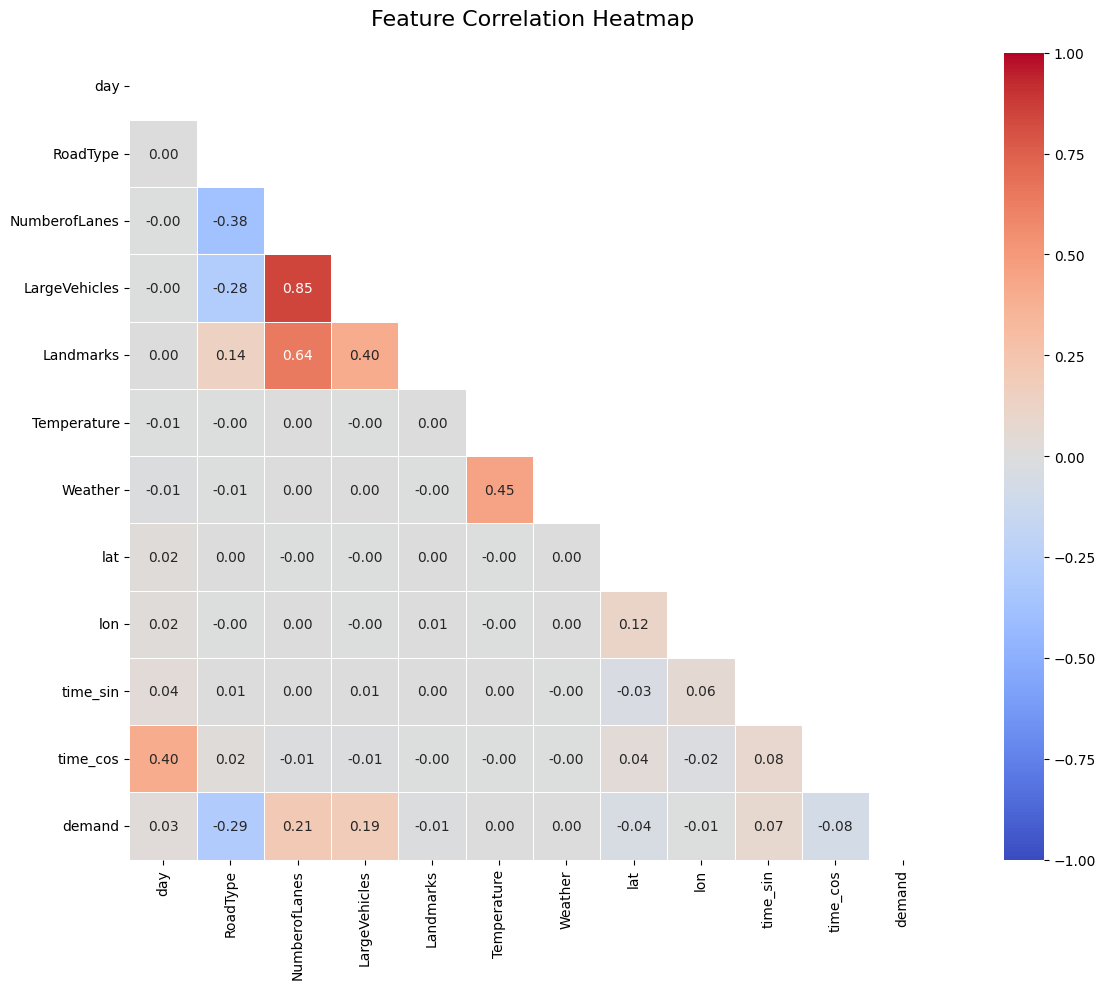

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Combine preprocessed features and target into a single DataFrame for correlation
corr_df = X_train_full.copy()
corr_df['demand'] = y_train_full

# Calculate the Pearson correlation matrix
corr_matrix = corr_df.corr()

# Create a mask to hide the upper triangle for a cleaner look
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Set up the matplotlib figure
plt.figure(figsize=(14, 10))

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,          # Shows the correlation numbers
    fmt=".2f",           # Formats numbers to 2 decimal places
    cmap='coolwarm',     # Blue for negative, Red for positive correlation
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=.5
)

plt.title('Feature Correlation Heatmap', fontsize=16, pad=20)
plt.tight_layout()
plt.show()